In [1]:
pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, classification_report,
                             ConfusionMatrixDisplay, RocCurveDisplay)

sns.set_theme(style="whitegrid")
os.makedirs("charts", exist_ok=True)

In [3]:
df = pd.read_csv("bank-full.csv", sep=";")   # this file uses ; as the separator
print("Shape:", df.shape)
df.head()

Shape: (45211, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        45211 non-null  int64 
 1   job        45211 non-null  object
 2   marital    45211 non-null  object
 3   education  45211 non-null  object
 4   default    45211 non-null  object
 5   balance    45211 non-null  int64 
 6   housing    45211 non-null  object
 7   loan       45211 non-null  object
 8   contact    45211 non-null  object
 9   day        45211 non-null  int64 
 10  month      45211 non-null  object
 11  duration   45211 non-null  int64 
 12  campaign   45211 non-null  int64 
 13  pdays      45211 non-null  int64 
 14  previous   45211 non-null  int64 
 15  poutcome   45211 non-null  object
 16  y          45211 non-null  object
dtypes: int64(7), object(10)
memory usage: 5.9+ MB


In [5]:
df.describe()

,age,balance,day,duration,campaign,pdays,previous
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,15.806419,258.163080,2.763841,40.197828,0.580323
std,10.618762,3044.765829,8.322476,257.527812,3.098021,100.128746,2.303441
min,18.000000,-8019.000000,1.000000,0.000000,1.000000,-1.000000,0.000000
25%,33.000000,72.000000,8.000000,103.000000,1.000000,-1.000000,0.000000
50%,39.000000,448.000000,16.000000,180.000000,2.000000,-1.000000,0.000000
75%,48.000000,1428.000000,21.000000,319.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,31.000000,4918.000000,63.000000,871.000000,275.000000


In [6]:
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

Missing values: 0
Duplicate rows: 0


y
no     39922
yes     5289
Name: count, dtype: int64
y
no     0.883
yes    0.117
Name: proportion, dtype: float64


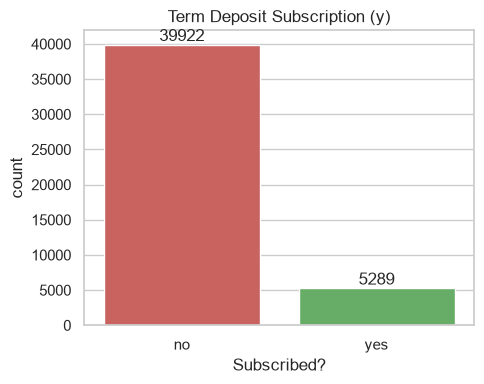

In [7]:
print(df["y"].value_counts())
print(df["y"].value_counts(normalize=True).round(3))

plt.figure(figsize=(5, 4))
ax = sns.countplot(data=df, x="y", hue="y", palette=["#d9534f", "#5cb85c"], legend=False)
for c in ax.containers:
    ax.bar_label(c)
plt.title("Term Deposit Subscription (y)")
plt.xlabel("Subscribed?")
plt.tight_layout()
plt.savefig("charts/01_target_distribution.png", dpi=150)
plt.show()

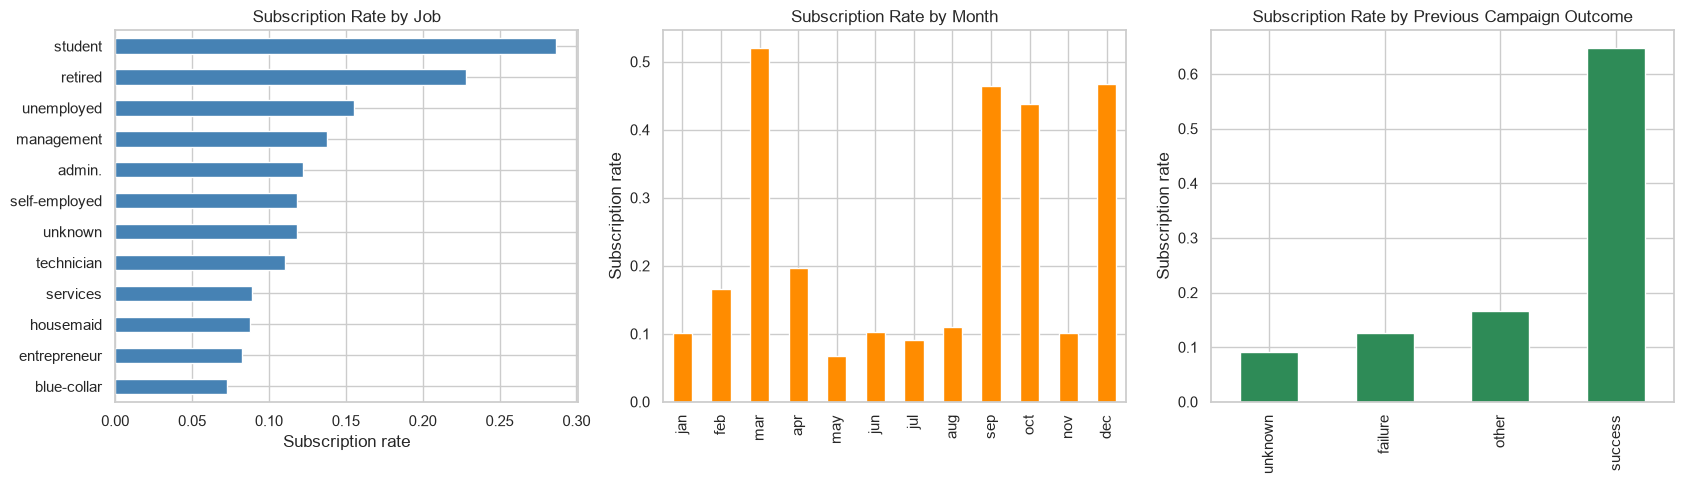

housing
no     0.167
yes    0.077
Name: target, dtype: float64
contact
cellular     0.149
telephone    0.134
unknown      0.041
Name: target, dtype: float64


In [8]:
df["target"] = (df["y"] == "yes").astype(int)

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

job_rate = df.groupby("job")["target"].mean().sort_values()
job_rate.plot(kind="barh", color="steelblue", ax=axes[0])
axes[0].set_title("Subscription Rate by Job")
axes[0].set_xlabel("Subscription rate")
axes[0].set_ylabel("")

months = ["jan","feb","mar","apr","may","jun","jul","aug","sep","oct","nov","dec"]
month_rate = df.groupby("month")["target"].mean().reindex(months)
month_rate.plot(kind="bar", color="darkorange", ax=axes[1])
axes[1].set_title("Subscription Rate by Month")
axes[1].set_xlabel("")
axes[1].set_ylabel("Subscription rate")

df.groupby("poutcome")["target"].mean().sort_values().plot(kind="bar", color="seagreen", ax=axes[2])
axes[2].set_title("Subscription Rate by Previous Campaign Outcome")
axes[2].set_xlabel("")
axes[2].set_ylabel("Subscription rate")

plt.tight_layout()
plt.savefig("charts/02_subscription_rates.png", dpi=150)
plt.show()

print(df.groupby("housing")["target"].mean().round(3))
print(df.groupby("contact")["target"].mean().round(3))

In [9]:
y = (df["y"] == "yes").astype(int)

X = pd.get_dummies(df.drop(columns=["duration", "y", "target"], errors="ignore"),
                   drop_first=True)

print("Features shape:", X.shape)
X.head()

Features shape: (45211, 41)


,age,balance,day,campaign,pdays,previous,job_blue-collar,job_entrepreneur,job_housemaid,job_management,...,month_jul,month_jun,month_mar,month_may,month_nov,month_oct,month_sep,poutcome_other,poutcome_success,poutcome_unknown
0,58,2143,5,1,-1,0,False,False,False,True,...,False,False,False,True,False,False,False,False,False,True
1,44,29,5,1,-1,0,False,False,False,False,...,False,False,False,True,False,False,False,False,False,True
2,33,2,5,1,-1,0,False,True,False,False,...,False,False,False,True,False,False,False,False,False,True
3,47,1506,5,1,-1,0,True,False,False,False,...,False,False,False,True,False,False,False,False,False,True
4,33,1,5,1,-1,0,False,False,False,False,...,False,False,False,True,False,False,False,False,False,True


In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Yes rate  train:", round(y_train.mean(), 3), "| test:", round(y_test.mean(), 3))

Train: (36168, 41) | Test: (9043, 41)
Yes rate  train: 0.117 | test: 0.117


In [11]:
def evaluate(model, X_t, y_t):
    pred = model.predict(X_t)
    proba = model.predict_proba(X_t)[:, 1]
    return {
        "Accuracy": accuracy_score(y_t, pred),
        "Precision": precision_score(y_t, pred),
        "Recall": recall_score(y_t, pred),
        "F1": f1_score(y_t, pred),
        "ROC AUC": roc_auc_score(y_t, proba),
    }

base = DecisionTreeClassifier(random_state=42).fit(X_train, y_train)
print("Depth:", base.get_depth(), "| Leaves:", base.get_n_leaves())
print("Train accuracy:", round(base.score(X_train, y_train), 3))
print("Test results:", {k: round(v, 3) for k, v in evaluate(base, X_test, y_test).items()})

Depth: 44 | Leaves: 4885
Train accuracy: 1.0
Test results: {'Accuracy': 0.83, 'Precision': 0.297, 'Recall': 0.331, 'F1': 0.313, 'ROC AUC': 0.614}


In [12]:
param_grid = {
    "max_depth": [3, 4, 5, 6, 8, 10],
    "min_samples_leaf": [20, 50, 100],
}

grid = GridSearchCV(
    DecisionTreeClassifier(random_state=42, class_weight="balanced"),
    param_grid, scoring="roc_auc", cv=5, n_jobs=-1
)
grid.fit(X_train, y_train)

print("Best parameters:", grid.best_params_)
print("Best cross-validated ROC AUC:", round(grid.best_score_, 3))
best = grid.best_estimator_

Best parameters: {'max_depth': 10, 'min_samples_leaf': 50}
Best cross-validated ROC AUC: 0.768


In [13]:
results = evaluate(best, X_test, y_test)
print({k: round(v, 3) for k, v in results.items()})
print()
print(classification_report(y_test, best.predict(X_test), target_names=["No", "Yes"]))

{'Accuracy': 0.808, 'Precision': 0.326, 'Recall': 0.597, 'F1': 0.422, 'ROC AUC': 0.778}

              precision    recall  f1-score   support

          No       0.94      0.84      0.89      7985
         Yes       0.33      0.60      0.42      1058

    accuracy                           0.81      9043
   macro avg       0.63      0.72      0.65      9043
weighted avg       0.87      0.81      0.83      9043



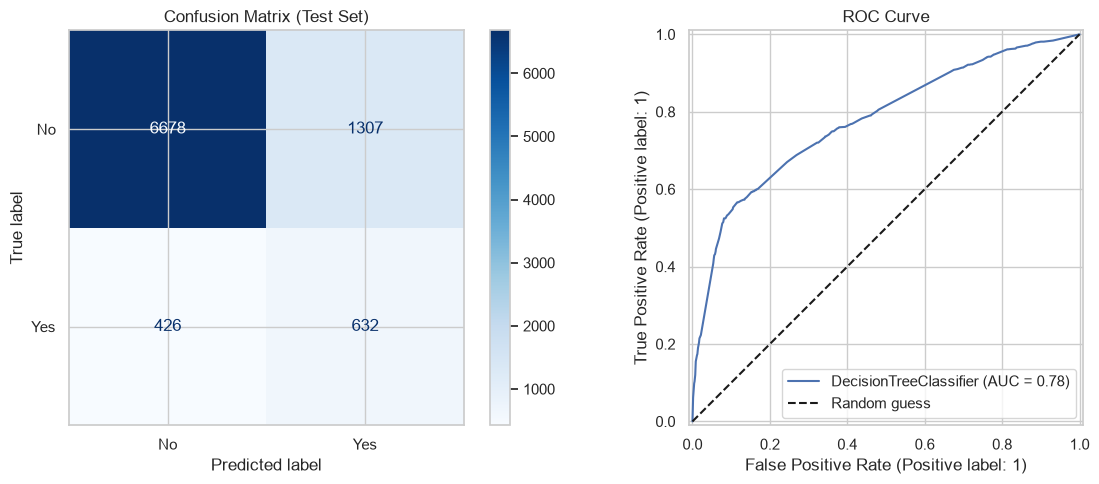

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay.from_estimator(best, X_test, y_test, display_labels=["No", "Yes"],
                                      cmap="Blues", ax=axes[0])
axes[0].set_title("Confusion Matrix (Test Set)")

RocCurveDisplay.from_estimator(best, X_test, y_test, ax=axes[1])
axes[1].plot([0, 1], [0, 1], "k--", label="Random guess")
axes[1].set_title("ROC Curve")
axes[1].legend()

plt.tight_layout()
plt.savefig("charts/03_confusion_matrix_roc.png", dpi=150)
plt.show()

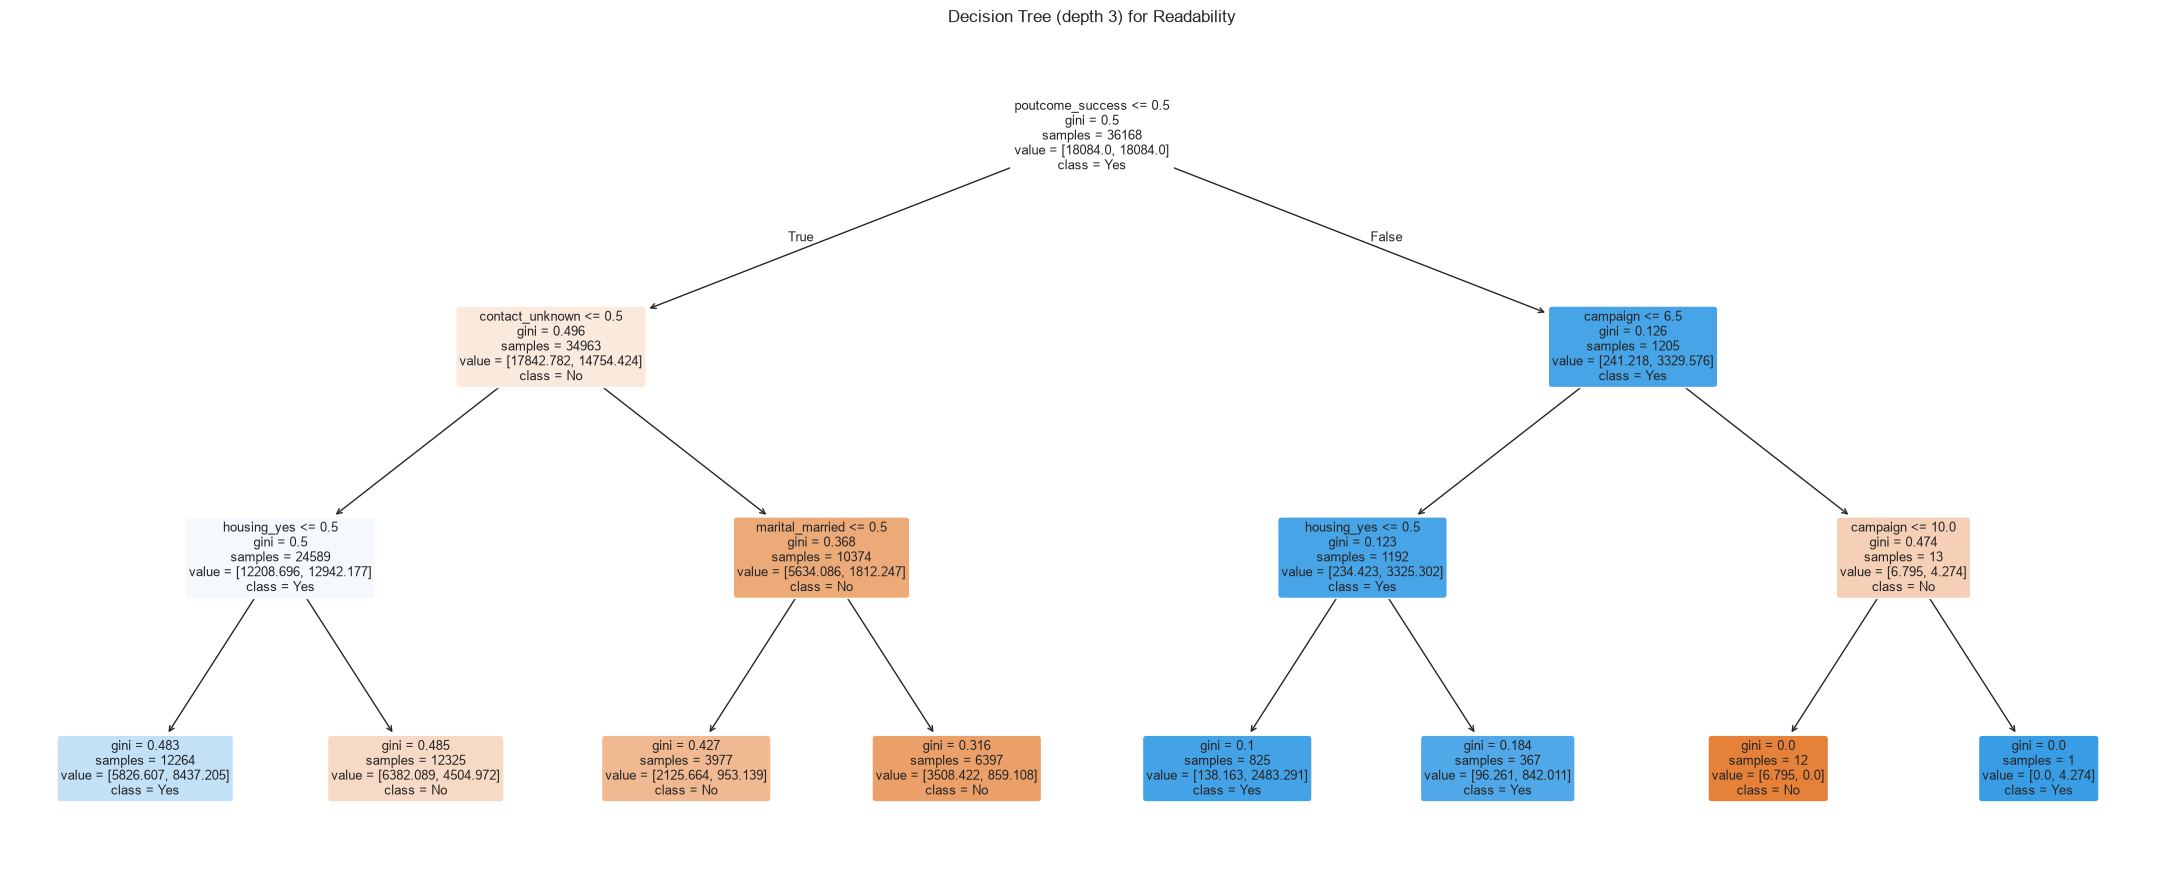

In [15]:
small_tree = DecisionTreeClassifier(max_depth=3, class_weight="balanced", random_state=42)
small_tree.fit(X_train, y_train)

plt.figure(figsize=(22, 9))
plot_tree(small_tree, feature_names=X.columns, class_names=["No", "Yes"],
          filled=True, rounded=True, fontsize=9)
plt.title("Decision Tree (depth 3) for Readability")
plt.tight_layout()
plt.savefig("charts/04_decision_tree_depth3.png", dpi=150)
plt.show()

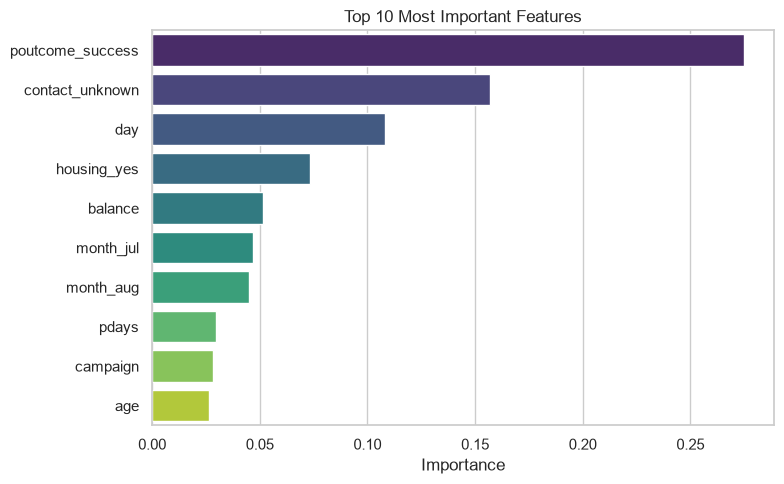

poutcome_success    0.275
contact_unknown     0.157
day                 0.108
housing_yes         0.073
balance             0.052
month_jul           0.047
month_aug           0.045
pdays               0.030
campaign            0.028
age                 0.026
dtype: float64

In [16]:
importance = pd.Series(best.feature_importances_, index=X.columns).sort_values(ascending=False).head(10)

plt.figure(figsize=(8, 5))
sns.barplot(x=importance.values, y=importance.index, hue=importance.index,
            palette="viridis", dodge=False, legend=False)
plt.title("Top 10 Most Important Features")
plt.xlabel("Importance")
plt.ylabel("")
plt.tight_layout()
plt.savefig("charts/05_feature_importance.png", dpi=150)
plt.show()

importance.round(3)

In [17]:
X_dur = pd.get_dummies(df.drop(columns=["y", "target"]), drop_first=True)
Xd_train, Xd_test, yd_train, yd_test = train_test_split(
    X_dur, y, test_size=0.2, random_state=42, stratify=y
)

with_duration = DecisionTreeClassifier(**best.get_params()).fit(Xd_train, yd_train)

comparison = pd.DataFrame({
    "Without duration (realistic)": evaluate(best, X_test, y_test),
    "With duration (benchmark only)": evaluate(with_duration, Xd_test, yd_test),
}).round(3)
comparison

,Without duration (realistic),With duration (benchmark only)
Accuracy,0.808,0.808
Precision,0.326,0.367
Recall,0.597,0.879
F1,0.422,0.518
ROC AUC,0.778,0.904


## Summary and conclusions
1. Data: 45,211 clients, 16 features, no missing values. Only 11.7% subscribed, so the classes are imbalanced.
2. Preparation: removed duration to avoid data leakage, one-hot encoded categorical columns, stratified 80/20 split.
3. Overfitting: the unrestricted tree reached 100% training accuracy but only 0.61 ROC AUC on test data.
4. Tuned model: max_depth=10 and min_samples_leaf=50 with balanced class weights gave ROC AUC 0.78, recall 60% and precision 33%, finding 632 of 1,058 subscribers.
5. Key drivers: previous campaign success, contact type, day and month of contact, housing loan.
6. Business takeaway: target clients with a previous success, students, retired clients and clients without housing loans, and avoid low-yield periods like May.
7. Limitations: a single decision tree is simple and interpretable but not the most accurate model. Random forests or gradient boosting would likely do better. Precision is low, so many flagged clients still won't subscribe.

Data source: Moro, Rita and Cortez (2014), Bank Marketing, UCI Machine Learning Repository, https://doi.org/10.24432/C5K306 (CC BY 4.0).